In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import time

from tensorflow.keras import layers, models
from tensorflow.keras.datasets import cifar10

In [2]:
(x_train, y_train), (x_test, y_test) = cifar10.load_data()

print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", x_test.shape)
print("Testing labels:", y_test.shape)

  3473408/170498071 ━━━━━━━━━━━━━━━━━━━━ 1:00:10 22us/step

KeyboardInterrupt: 

In [ ]:
class_names = [
    'airplane',
    'automobile',
    'bird',
    'cat',
    'deer',
    'dog',
    'frog',
    'horse',
    'ship',
    'truck'
]

print("Classes:", class_names)
print("Number of classes:", len(class_names))

Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Number of classes: 10


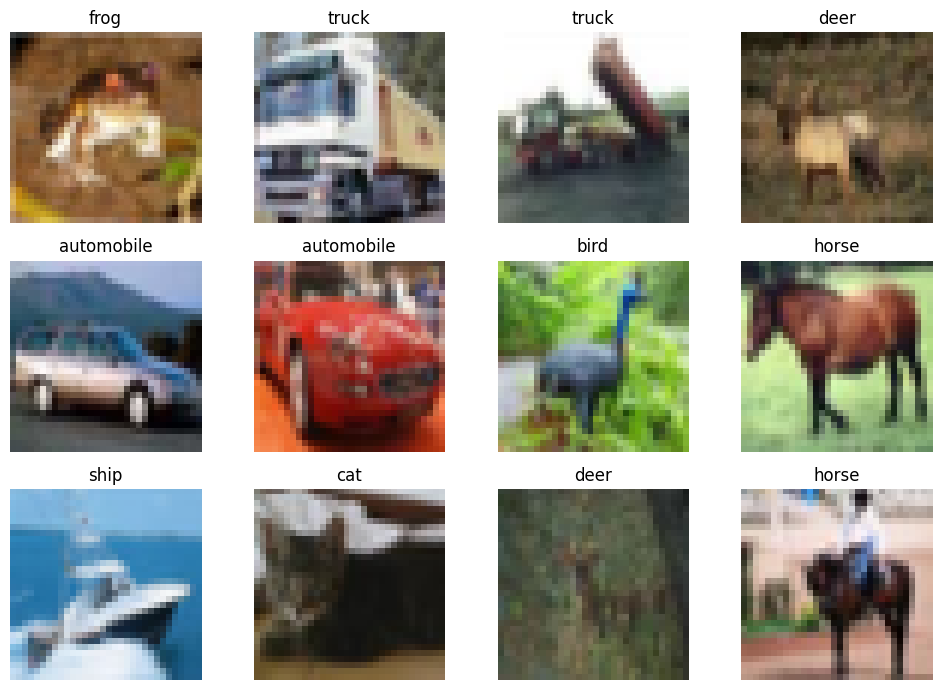

In [ ]:
plt.figure(figsize=(10, 7))

for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(x_train[i])
    plt.title(class_names[y_train[i][0]])
    plt.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
IMG_SIZE = 224
NUM_CLASSES = 10
BATCH_SIZE = 32

print("Image size:", IMG_SIZE)
print("Number of classes:", NUM_CLASSES)
print("Batch size:", BATCH_SIZE)

Image size: 224
Number of classes: 10
Batch size: 32


In [ ]:
def resize_image(image, label):
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    image = tf.cast(image, tf.float32)
    label = tf.squeeze(label)
    return image, label


# Create TensorFlow datasets
train_ds = tf.data.Dataset.from_tensor_slices((x_train, y_train))
test_ds = tf.data.Dataset.from_tensor_slices((x_test, y_test))

# Resize images
train_ds = train_ds.map(
    resize_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

test_ds = test_ds.map(
    resize_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

# Shuffle, batch and prefetch
train_ds = train_ds.shuffle(10000).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
test_ds = test_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Testing batches:", tf.data.experimental.cardinality(test_ds).numpy())

Training batches: 1563
Testing batches: 313


In [ ]:
id="q7x2km"
for images, labels in train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Image data type:", images.dtype)

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Image data type: <dtype: 'float32'>


In [ ]:
from tensorflow.keras.applications import VGG16

vgg_base = VGG16(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

print("VGG16 loaded successfully!")
print("Number of layers:", len(vgg_base.layers))

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
VGG16 loaded successfully!
Number of layers: 19


In [ ]:
vgg_base.trainable = False

print("VGG16 trainable:", vgg_base.trainable)

trainable_layers = sum(layer.trainable for layer in vgg_base.layers)
print("Trainable layers:", trainable_layers)
print("Total layers:", len(vgg_base.layers))

VGG16 trainable: False
Trainable layers: 0
Total layers: 19


In [ ]:
vgg_model = models.Sequential([
    vgg_base,
    layers.GlobalAveragePooling2D(),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(NUM_CLASSES, activation='softmax')
])

print("VGG16 transfer learning model created!")

VGG16 transfer learning model created!


In [ ]:
vgg_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("VGG16 model compiled successfully!")

VGG16 model compiled successfully!
